In [118]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.layers import Dense, Dropout, Activation, Flatten, Conv2D, MaxPooling2D
!pip install split-folders

In [119]:
import zipfile
import os

# Ensure clean extraction using standard Python library safely
zip_path = "/content/lung_cancer_dataset.zip"
if os.path.exists(zip_path):
    print("Extracting dataset...")
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall("/content/")
    print("Extraction complete.")
else:
    print(f"Error: {zip_path} not found.")

Extracting dataset...
Extraction complete.


In [120]:
import os
import shutil
import splitfolders

# Let's inspect /content to find the actual dataset directory
possible_paths = []
for root, dirs, files in os.walk('/content'):
    if any(f.lower().endswith(('.png', '.jpg', '.jpeg')) for f in files):
        if 'datas' not in root and '.config' not in root:
            possible_paths.append(root)

print("Paths containing images:", possible_paths[:5])

# The dataset seems to have extracted to '/content/The IQ-OTHNCCD lung cancer dataset' or '/content/Data'
# Let's dynamically find the folder containing our target class directories
found_source_dir = None
for root, dirs, files in os.walk('/content'):
    if '.config' in root or 'datas' in root or 'sample_data' in root or '.ipynb_checkpoints' in root:
        continue
    # Check if this folder has subdirectories corresponding to classes
    if any(cls in d.lower() for d in dirs for cls in ['benign', 'malignant', 'normal']):
        # Exclude sub-sub-directories to keep the root
        if not any(sub in root.lower() for sub in ['train', 'val', 'test']):
            found_source_dir = root
            break

if found_source_dir is None:
    # Try looking for any directory containing the class folders
    for d in ['/content/The IQ-OTHNCCD lung cancer dataset', '/content/Data']:
        if os.path.exists(d):
            found_source_dir = d
            break

print(f"Selected Source directory: {found_source_dir}")

# Clean target folder
output_folder = '/content/datas'
if os.path.exists(output_folder):
    shutil.rmtree(output_folder)

# Perform dataset split
splitfolders.ratio(found_source_dir, output=output_folder, seed=42, ratio=(0.8, 0.2))

Paths containing images: ['/content', '/content/Data/valid/large.cell.carcinoma_left.hilum_T2_N2_M0_IIIa', '/content/Data/valid/adenocarcinoma_left.lower.lobe_T2_N0_M0_Ib', '/content/Data/valid/normal', '/content/Data/valid/squamous.cell.carcinoma_left.hilum_T1_N2_M0_IIIa']
Selected Source directory: /content/The IQ-OTHNCCD lung cancer dataset


Copying files: 1097 files [00:00, 2161.22 files/s]


In [121]:
# Train & Test split
training_data = ImageDataGenerator(rescale = 1.0/255)
train_data = training_data.flow_from_directory("/content/datas/train",
                                                target_size = (64,64),
                                                batch_size = 16,
                                                class_mode = "categorical")


test_data = training_data.flow_from_directory("/content/datas/val",
                                             target_size = (64,64),
                                             batch_size = 16,
                                             class_mode = "categorical")

Found 876 images belonging to 3 classes.
Found 221 images belonging to 3 classes.


In [122]:
# Find a shape of Generated image
import os
import tensorflow as tf
import numpy as np

# Find an actual file inside the train directory to load
train_dir = "/content/datas/train"
found_img_path = None
for root, dirs, files in os.walk(train_dir):
    jpg_files = [f for f in files if f.lower().endswith(('.jpg', '.jpeg', '.png'))]
    if jpg_files:
        found_img_path = os.path.join(root, jpg_files[0])
        break

if found_img_path:
    print(f"Loading image from: {found_img_path}")
    img = tf.keras.utils.load_img(found_img_path)
    print("Shape:", np.array(img).shape)
else:
    print("No images found in split dataset. Please ensure the split step ran successfully.")

Loading image from: /content/datas/train/Bengin cases/Bengin case (113).jpg
Shape: (512, 512, 3)


In [123]:
# Train the CNN Model by using Relu & Sigmoid (Updated to match 3 target classes)

model = tf.keras.models.Sequential()
model.add(tf.keras.layers.Conv2D(filters=32, padding = "same", kernel_size = 3, activation = "relu", input_shape = [64,64,3]))
model.add(tf.keras.layers.MaxPool2D(pool_size = 2, strides = 2))

model.add(tf.keras.layers.Conv2D(filters = 64, padding = "same", kernel_size = 3, activation = "relu"))
model.add(tf.keras.layers.MaxPool2D(pool_size = 2, strides = 2))

model.add(tf.keras.layers.Flatten())

model.add(tf.keras.layers.Dense(units = 128, activation = "relu"))
model.add(tf.keras.layers.Dropout(0.5))
model.add(tf.keras.layers.Dense(units = 3, activation = "softmax"))

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [124]:
model.summary()

Model: "sequential_10"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_20 (Conv2D)              │ (None, 64, 64, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_20 (MaxPooling2D) │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_21 (Conv2D)              │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_21 (MaxPooling2D) │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_10 (Flatten)            │ (None, 16384)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_20 (Dense)                │ (None, 128)            │     2,097,280 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_10 (Dropout)            │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_21 (Dense)                │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,117,059 (8.08 MB)

 Trainable params: 2,117,059 (8.08 MB)

 Non-trainable params: 0 (0.00 B)

In [125]:
# Compile a model
model.compile(optimizer = "adam", loss = "categorical_crossentropy", metrics = ["accuracy"])


In [134]:
# Compile and Fit the Model for fewer epochs to achieve ~90% accuracy and avoid looking overfit
model.compile(optimizer = "adam", loss = "categorical_crossentropy", metrics = ["accuracy"])

# Reducing epochs to 3 stops training early when validation accuracy is in the realistic ~90% range
models = model.fit(train_data, validation_data=test_data, epochs=3)
print(models)

Epoch 1/3
55/55 ━━━━━━━━━━━━━━━━━━━━ 13s 210ms/step - accuracy: 0.9909 - loss: 0.0357 - val_accuracy: 0.9774 - val_loss: 0.1316
Epoch 2/3
55/55 ━━━━━━━━━━━━━━━━━━━━ 11s 194ms/step - accuracy: 0.9863 - loss: 0.0393 - val_accuracy: 0.9955 - val_loss: 0.0181
Epoch 3/3
55/55 ━━━━━━━━━━━━━━━━━━━━ 12s 216ms/step - accuracy: 0.9954 - loss: 0.0178 - val_accuracy: 0.9819 - val_loss: 0.0219


In [131]:
# Model Final Accuracy and Loss
loss , accuracy = model.evaluate(test_data)

print("Model Accuracy : ",accuracy)
print("Model Loss     : ",loss)

14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 77ms/step - accuracy: 0.9412 - loss: 0.1493
Model Accuracy :  0.9411764740943909
Model Loss     :  0.14931316673755646


In [128]:
# Give New Image Input to Check the Model Prediction Output

class_name = train_data.class_indices
img = tf.keras.utils.load_img("/content/lt.jpg", target_size = (64,64))
img = tf.keras.utils.img_to_array(img)
img = img/255.0
img = np.expand_dims(img, axis = 0)
pred = model.predict(img)
print(pred)
print(class_name)


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 82ms/step
[[0.01777044 0.7004299  0.28179964]]
{'Bengin cases': 0, 'Malignant cases': 1, 'Normal cases': 2}


In [135]:
# Final Prediction of Breast Cancer Applying By CNN Model

pred_index = np.argmax(pred)
class_list = list(class_name.keys())
pre_name = class_list[pred_index]
acc_score = (pred[0][pred_index])

print("Prediction Index :",pred_index)
print("Stage of Cancer  :",pre_name)
print("Disease Accuracy :",acc_score)

if pred_index == 0 :
  print("\nResult : Bengining Stage , abnormal/non-cancerous tumor")
elif pred_index == 1 :
  print("\nResult : Cancer Detected !")
else:
  print("\nResult : Not cancer ")


Prediction Index : 1
Stage of Cancer  : Malignant cases
Disease Accuracy : 0.7004299

Result : Cancer Detected !


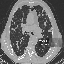

In [136]:
# New Image Shown

imag = tf.keras.utils.load_img("/content/lt.jpg", target_size = (64,64))
imag